# NP1 - L2

## Parte teórica (5 pontos cada)

Classifique as afirmações em Verdadeiro ou Falso, justifique as afirmativas falsas

1 - As imagens matricias são mais usadas em logos, pois apresentam serrilhamento quando são ampliadas

**Resposta**: Falso, as imagens vetoriais são mais usadas em logos por não apresentarem serrilhamento.

2 - O padrão de cores CMY é utilizado em impressões, enquanto o RGB é usado em displays.

**Resposta**: Verdadeiro

3 - O código abaixo é usado para importar uma imagem e retirar o terceiro campo de cor (Blue, ou azul, do RGB)

```imagem = np.array(Image.open('Clara.png'))[:, :, :3]```

**Resposta**: Falso, o código importa a imagem retirando o canal alpha e deixando os canais RGB e no final transforma tudo em um array NumPy.

4 -  A lógica OR aplicada em uma imagem detecta os pixels que não mudaram de valor

**Resposta**: Falso, a operação OR em uma imagem detectaria apenas onde há pixels nas imagens, sendo que a operação que detectaria quais pixels não mudaram de valor seria a operação XNOR.

5 - O padrão de cores CMY é o mais próximo da visão humana.

**Resposta**: Falso, o padrão de cores mais próximo da visão humana é o HSV, modelo que é "orientado a humanos", uma vez que é de mais fácil escolha, podendo ser escolhido a cor(H-Hue), a saturação(S-Saturation) e o valor do brilho(V-Value) de forma mais interativa e adapatada.

# Parte prática (5 pontos cada, exceto a questão 11 que vale 10)

## Material de apoio

### Importações

```python
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
```

### Manipulação de imagens

```python
img = Image.open('nome.extensão')
img = np.array(Image.open('nome.extensão'))
img = img[:, :, :3]
img_pil = Image.fromarray(img_np)
img.save('nome.png')
Image.fromarray(img).save('nome_arquivo.extensao')
(l,c,p) = img.shape
```

### Greyscale

#### Algoritmo genérico, substituir o método escolhido
```python
img_avg = np.zeros(shape=(l, c), dtype=np.uint8)
for i in range(l):
    for j in range(c):
        r = float(img_np[i, j, 0])
        g = float(img_np[i, j, 1])
        b = float(img_np[i, j, 2])
        
        img_avg[i, j] = (aplicar método)
```

#### Métodos:


Lightness: $\frac{max(R,G,B)+min(R,G,B)}{2}$


Average: $\frac{R+G+B}{3}$


Luminosity: $0.2126 \cdot R + 0.7152 \cdot G + 0.0722 \cdot B$


RGB para CMY:
### <font color="red">R</font><font color="green">G</font><font color="blue">B</font> para <font color="cyan">C</font><font color="magenta">M</font><font color="yellow">Y</font>
$$\begin{pmatrix}
    C \\ M \\ Y
\end{pmatrix} = \begin{pmatrix}
    1 \\ 1 \\ 1
\end{pmatrix} - \begin{pmatrix}
    R \\ G \\ B
\end{pmatrix} e \begin{pmatrix}
    R \\ G \\ B
\end{pmatrix} = \begin{pmatrix}
    1 \\ 1 \\ 1
\end{pmatrix} - \begin{pmatrix}
    C \\ M \\ Y
\end{pmatrix}$$
* **<font color="red">R</font>** + **<font color="cyan">C</font>** = 1 (ou 255);
* **<font color="green">G</font>** + **<font color="magenta">M</font>** = 1;
* **<font color="blue">B</font>** + **<font color="yellow">Y</font>** = 1.


Interpolação Bilinear:
Seja $I$ a imagem de entrada $L_{entrada}×C_{entrada}$ e $J$ a imagem de saída $L_{saída}×C_{saída}.$

Seja $s_L = L_{entrada}/L_{saída}$ e $s_C = C_{entrada}/C_{saída}.$

Seja $l_f = l \cdot s_L$ para $r=0,\ldots,R_{saída}-1$ e $c_f = c \cdot s_C$ para $c=0,\ldots,C_{saída}-1.$

Seja $r_0 = \lfloor{l_f}\rfloor$ e $c=\lfloor{c_f}\rfloor.$

Seja $\Delta_l = l_f - l_0$ e $\Delta_c = c_f - c_0.$

Então $J(l, c)$
$$=I(l_0, c_0) \cdot (1-\Delta_l) \cdot (1-\Delta_c)$$
$$+I(l_0+1, c_0) \cdot \Delta_l \cdot (1-\Delta_c)$$
$$+I(l_0, c_0+1) \cdot (1-\Delta_l) \cdot \Delta_c$$
$$+I(l_0+1, c_0+1) \cdot \Delta_l \cdot \Delta_c.$$

### Escalonamento com nearest neighbor

```python
ls, cs = l * sy, c * sx
mario_nn = np.zeros(shape=(ls, cs, p), dtype=np.uint8)

for i in range(ls):
    for j in range(cs):
        new_y = int(np.floor(i * (l / ls)))
        new_x = int(np.floor(j * (c / cs)))
        
        mario_nn[i, j] = mario[new_y, new_x]
```
### Escalonamento clássico
```python
scale_x, scale_y = 2, 2
mario_scale = np.zeros(shape=(l * scale_y, c * scale_x, p), dtype=np.uint8)
for i in range(l):
    for j in range(c):
        new_x = np.round(j * scale_x)
        new_y = np.round(i * scale_y)
        mario_scale[new_y, new_x] = mario[i, j]

plt.imshow(mario_scale)
Image.fromarray(mario_scale).save('mario_scale.png')
```

### Cisalhamento

```python
img_shear = np.zeros((int(l * (1.1 + cy)), int(c * (1.1 + cx)), p), dtype=np.uint8)
for i in range(l):
    for j in range(c):
        new_x = int(j + cx * i)
        new_y = int(cy * j + i)
        
        img_shear[new_y, new_x] = img[i, j]
```

### Imagem grayscale para imagem binária de 3 canais

```python
bin = np.zeros(shape=(l,c,3),dtype=np.uint8)
    
for i in range(l):
    for j in range(c):
        if img[i,j] > thresh:
            bin[i,j,:] = 255
        else:
            bin[i,j,:] = 0

```
### Blending com escala genérica

```python
imagem_blending = (C * img_1) + ((1 - C) * img_2)
imagem_blending = imagem_blending.astype(np.uint8)
```

### Histograma
```python
def histogram_gray(img):
    (l, c) = img.shape
    histogram = np.zeros(256, dtype=np.int32)

    for i in range(l):
        for j in range(c):
            intensity = img[i, j]
            histogram[intensity] += 1
            
    return histogram

def show_histogram_gray(img):
    histogram = histogram_gray(img)
    plt.figure(figsize=(16, 16))
    plt.subplot(2, 1, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.subplot(2, 1, 2)
    plt.bar(range(256), histogram)

def show_histogram(img):
    histogram_r = histogram_gray(img[:, :, 0])
    histogram_g = histogram_gray(img[:, :, 1])
    histogram_b = histogram_gray(img[:, :, 2])
    
    plt.figure(figsize=(16, 16))
    plt.subplot(2, 1, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.subplot(2, 1, 2)
    plt.bar(range(256), histogram_r, color='red')
    plt.bar(range(256), histogram_g, color='green')
    plt.bar(range(256), histogram_b, color='blue')

```
### Espelhamento
```python
refl = np.zeros(shape=example.shape, dtype=np.uint8)
for i in range(l):
    for j in range(c):
        new_x = -j
        new_y = i
        refl[new_y, new_x] = example[i, j]

plt.imshow(refl)
```


No outro eixo

```python
refl = np.zeros(shape=example.shape, dtype=np.uint8)
refl[::-1, ::1] = example
plt.imshow(refl)
```

### Detecção de bordas
```python
abs_tg_c = np.abs(np.diff(museum.astype(np.float64), axis=0, append=255))

abs_tg_l = np.abs(np.diff(museum.astype(np.float64), axis=1, append=255))

abs_tg = np.sqrt(abs_tg_c ** 2 + abs_tg_l ** 2)

threshold = 16
museum_border = np.zeros(shape=(l, c), dtype=np.uint8)
museum_border[abs_tg > threshold] = 255
```

### Operações lógicas
NOT:
```python
bin1_not = np.bitwise_not(bin1)
bin2_not = np.invert(bin2)
```
AND:
```python
bin_and = np.bitwise_and(bin1, bin2)
```
OR:
```python
bin_or = np.bitwise_or(bin1, bin2)
```
XOR
```python
bin_xor = np.bitwise_xor(bin1, bin2)
```

**1 - (5 pontos)** Importe as bibliotecas que serão usadas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

**2 - (5 pontos)** Abra as imagens techno.jpg, Shrine.jpg e Ninja.jpg, retire o canal alpha se necessário, exiba essas imagens e mostre o formato de cada uma

Formato da techno.jpg: (500, 500, 3)


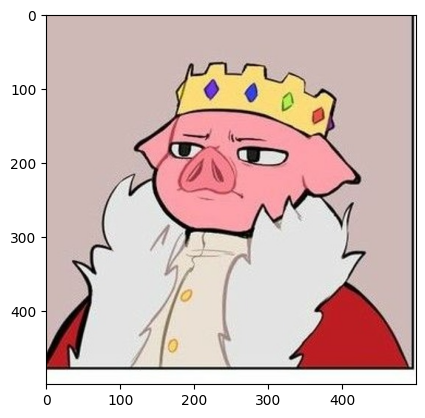

In [2]:
#Para a imagem techno.jpg
techno = np.array(Image.open('techno.jpg'))[:, :, :3]
print(f"Formato da techno.jpg: {techno.shape}")
plt.imshow(techno)

Formato da Shrine.jpg: (500, 500, 3)


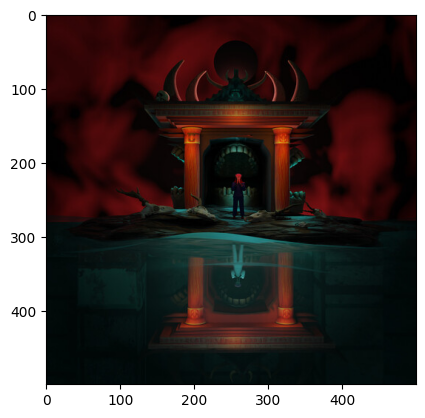

In [6]:
#Para a imagem Shrine.jpg
shrine = np.array(Image.open('Shrine.jpg'))[:, :, :3]
print(f"Formato da Shrine.jpg: {shrine.shape}")
plt.imshow(shrine)

Formato da Ninja.jpg: (250, 250, 3)


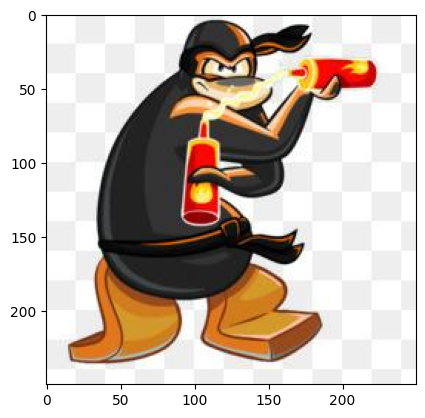

In [7]:
#Para a Ninja.jpg
ninja = np.array(Image.open('Ninja.jpg'))[:, :, :3]
print(f"Formato da Ninja.jpg: {ninja.shape}")
plt.imshow(ninja)

**3 - (5 pontos)** Crie uma função que realize o escalonamento de uma imagem para que Ninja e Techno fiquem do mesmo tamanho. Utilize o método de sua preferência e mostre o resultado

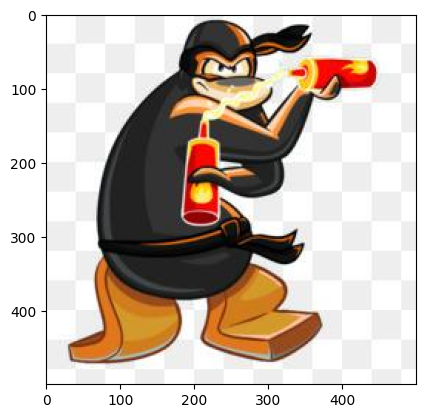

In [11]:
def escalonamento(imagem1:np.array, imagem2:np.array)->np.array:
    # Dimensões originais
    l1, c1, p1 = imagem1.shape
    l2, c2, p2 = imagem2.shape

    # Cria array vazio para a nova imagem
    imagem_nn = np.zeros(shape=(l2, c2, p2), dtype=np.uint8)

    # Percorre cada pixel da imagem DESTINO
    for i in range(l2):
        for j in range(c2):
            # Encontra o pixel correspondente na imagem ORIGINAL
            orig_y = int(np.floor(i * (l1 / l2)))
            orig_x = int(np.floor(j * (c1 / c2)))

            # Copia o valor do pixel
            imagem_nn[i, j] = imagem1[orig_y, orig_x]

    return imagem_nn

# Exibe o resultado
resultado3 = escalonamento(ninja, techno)
plt.imshow(resultado3)

**4 - (10 pontos)** Aplique a espelhamento no eixo Y à imagem techno. Mostre o resultado

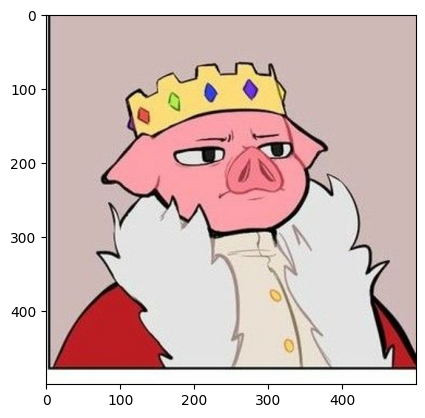

In [21]:
def mirror(img: np.array, reverse_x: bool, reverse_y: bool) -> np.array:
    l, c, p = img.shape
    img_refl = img.copy()

    if reverse_y:
        temp = np.zeros_like(img_refl)
        for i in range(l):
            for j in range(c):
                temp[i, (c - 1) - j] = img_refl[i, j]
        img_refl = temp

    if reverse_x:
        temp = np.zeros_like(img_refl)
        for i in range(l):
            for j in range(c):
                temp[(l - 1) - i, j] = img_refl[i, j]
        img_refl = temp

    return img_refl.astype(np.uint8)

resultado4 = mirror(techno, False, True)
plt.imshow(resultado4)

**5 - (10 pontos)** Aplique a técnica Greyscale a imagem resultante da questão 4. Mostre o resultado

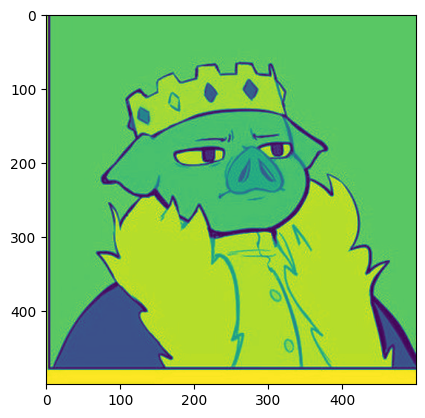

In [30]:
l, c, p = resultado4.shape
img_avg = np.zeros(shape = (l, c), dtype=np.uint8)
for i in range(l):
  for j in range(c):
    r = float(resultado4[i,j,0])
    g = float(resultado4[i,j,1])
    b = float(resultado4[i,j,2])

    img_avg[i,j] = 0.2126*r+0.7152*g+0.0722*b

plt.imshow(img_avg)

**6 - (10 pontos)** Crie uma função para transformar imagem RGB em CMY. Aplique a imagem da **questão 5**. Mostre o resultado

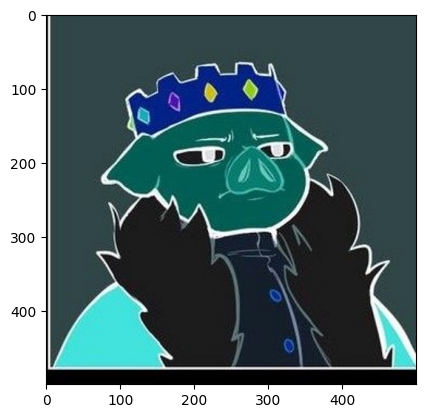

In [33]:
def rgb_to_cmy(imagem:np.array)->np.array:
    l, c, p = imagem.shape
    imagem_cmy = np.zeros(shape=(l, c, p), dtype=float)
    cy = 1 - imagem[:,:,0]/255.0
    ma = 1 - imagem[:,:,1]/255.0
    ye = 1 - imagem[:,:,2]/255.0
    imagem_cmy[:,:,0] = cy
    imagem_cmy[:,:,1] = ma
    imagem_cmy[:,:,2] = ye
    return (imagem_cmy*255.0).astype(np.uint8)

resultado6 = rgb_to_cmy(resultado4)
plt.imshow(resultado6)

**7 - (10 pontos)** Aplique a operação XOR com as imagens resultantes da questões 4 e 6. Mostre o resultado

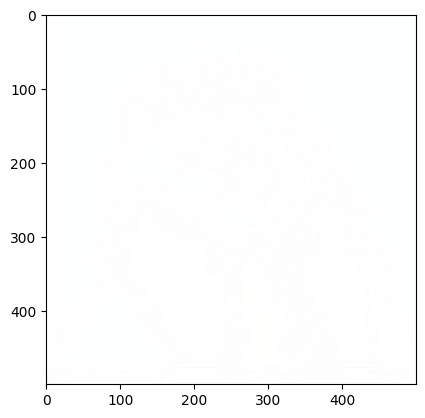

In [34]:
resultado7 = np.bitwise_xor(resultado4, resultado6)
plt.imshow(resultado7)

**8 - (10 pontos)** Aplique o escalonamento com nearest neighbor com fator sx = 1.5 e sy = 1.2 na imagem resultante na questão anterior, após isso salve a imagem no disco com o nome "resultado.jpg"

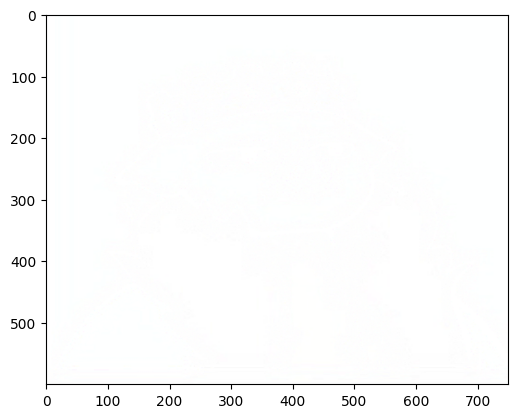

In [39]:
l, c, p = resultado7.shape
ls, cs = l * 1.2, c * 1.5
escalonado = np.zeros(shape=(int(ls), int(cs), p), dtype=np.uint8)

for i in range(int(ls)):
  for j in range(int(cs)):
      new_y = int(np.floor(i * (l / ls)))
      new_x = int(np.floor(j * (c / cs)))

      escalonado[i, j] = resultado7[new_y, new_x]

plt.imshow(escalonado)
Image.fromarray(escalonado).save('resultado.jpg')

**9 - (10 pontos)** Apresente o histograma da imagem da questão anterior. Mostre o resultado e explique o que pode ser deduzido a partir dele.

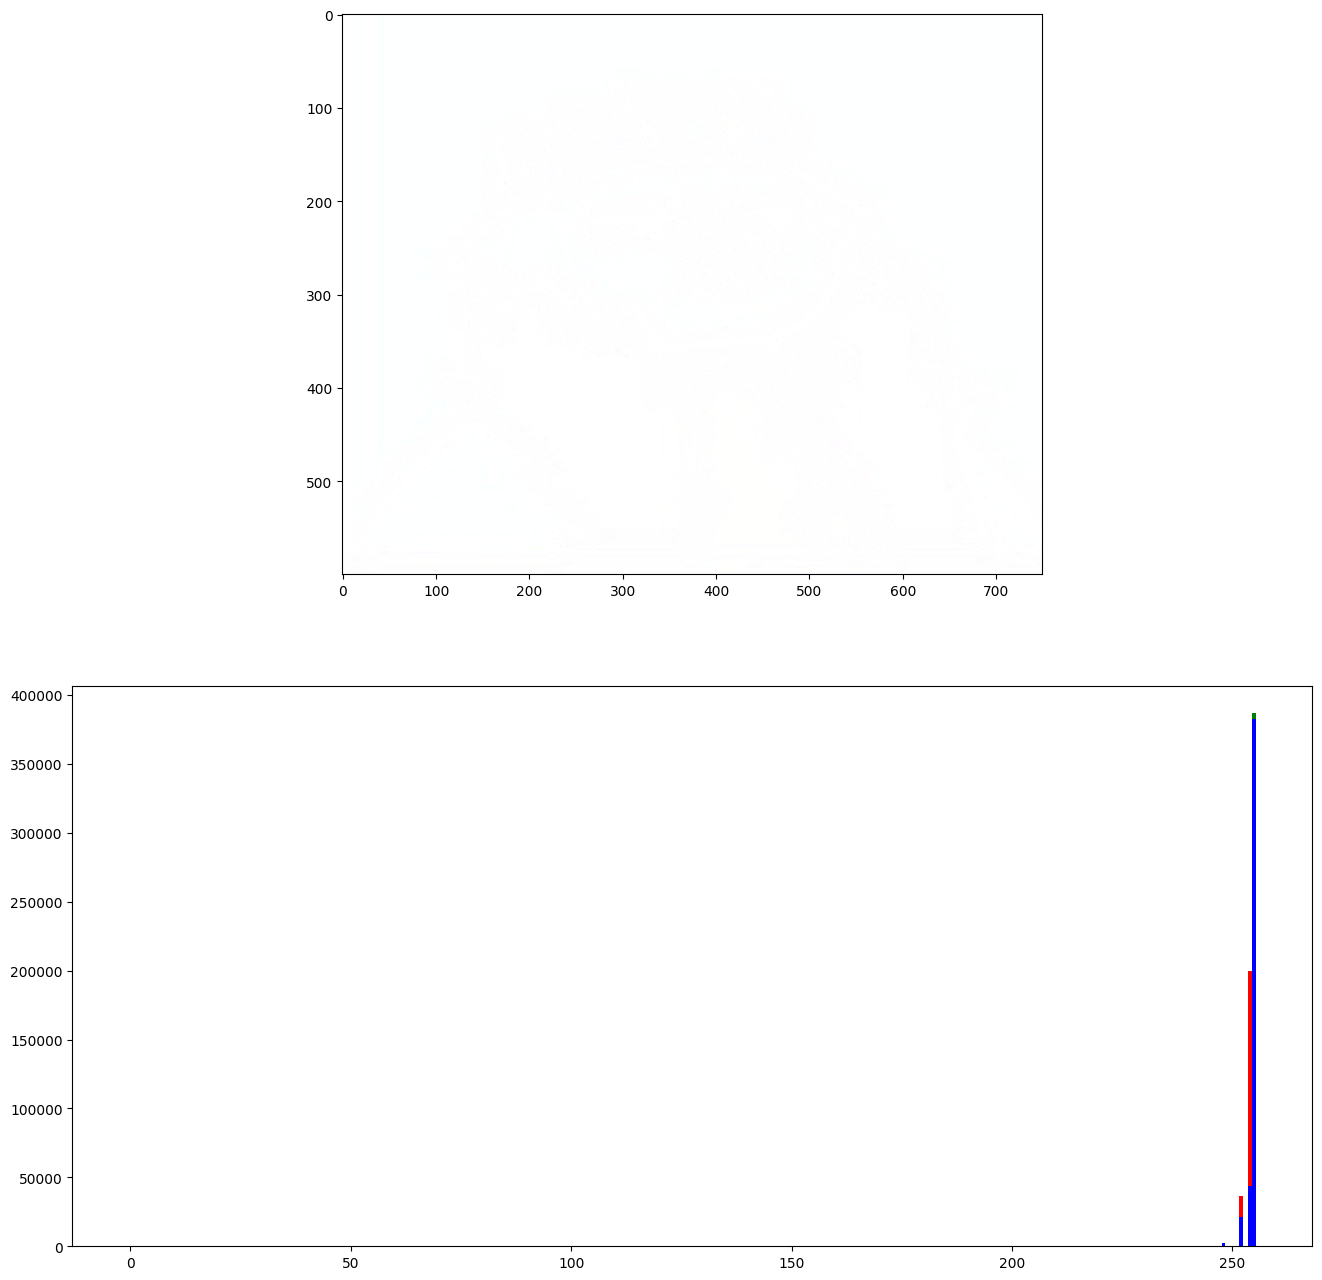

In [41]:
def histogram_gray(img):
    (l, c) = img.shape
    histogram = np.zeros(256, dtype=np.int32)

    for i in range(l):
        for j in range(c):
            intensity = img[i, j]
            histogram[intensity] += 1

    return histogram

def show_histogram_gray(img):
    histogram = histogram_gray(img)
    plt.figure(figsize=(16, 16))
    plt.subplot(2, 1, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.subplot(2, 1, 2)
    plt.bar(range(256), histogram)

def show_histogram(img):
    histogram_r = histogram_gray(img[:, :, 0])
    histogram_g = histogram_gray(img[:, :, 1])
    histogram_b = histogram_gray(img[:, :, 2])

    plt.figure(figsize=(16, 16))
    plt.subplot(2, 1, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.subplot(2, 1, 2)
    plt.bar(range(256), histogram_r, color='red')
    plt.bar(range(256), histogram_g, color='green')
    plt.bar(range(256), histogram_b, color='blue')

show_histogram(escalonado)

A partir do resultado do histograma, podemos deduzir que a imagem está quase inteiramente branca, visto que a distribuição das cores está inteiramente em um único canto do histograma. O que é fato, dado que a aplicação da operação XOR, operação que detecta se os pixels mudaram de posição, não se eles mudaram de cor, aplicada em duas imagens iguais, resulta em branco.

# Lembre de entregar tudo como um arquivo ZIP, com o arquivo resultado e seu notebook, NOMEADO COMO: "C09 - LX - SEU NOME COMPLETO"